## PVA 1 - Coding Kata

# __Aufgabe 1__

Zur Motivation ein paar Aussichten auf die Möglichkeiten des Deep Learning:
- Erstellt verschiedene Gruppenfotos der Klasse/Gruppe (nicht nur Frontalaufnahmen der Gesichter, leicht verdreht, ONLINE - eine Challenge, aber das schafft ihr schon)
- Erstelle mehrere Portraitfotos von Dir (mit leichter Rotation)
- Probiere *AWS Rekognition-> Face comparison* mit diesen Daten aus
- Diskutiert über die Funktionalität dieses Moduls
    - Ist das eine (überwachte oder nicht-überwachte) Klassifikation
    - Ist es Objekterkennung?
    - Wie könnten die Ähnlichkeiten bestimmt werden?

1. Überwachte oder nicht-überwachte Klassifikation?
2. Ist es Objekterkennung?
3. Wie könnten die Ähnlichkeiten bestimmt werden?

# __Aufgabe 2__

Es wird Data Science-Studenten oft vorgeworfen, sie verstünden Neuronale Netze nicht richtig, da sie immer vorgefertigte Bibliotheken verwenden. Das lassen wir nicht auf uns sitzen - wir programmieren uns ein eigenes Netz!

Achtung: Mir ist bewusst, dass es eine Unmenge an Beispielen im Netz gibt, die relativ einfach zu kopieren sind. Versucht dennoch ausgehend von den Formeln und Matrizzenkalkulationen für Neuronale Netze die Funktionen selbst zu erstellen.

- Konzipiere eine Neuronale Netzwerkklasse mit Funktionen fit() und predict()
- Implementiere die Klasse OHNE NN-Bibliotheken, verwende ausschliesslich generische Bibliotheken (wie numpy, etc.)
- Die Klasse soll nur *einen* Hidden Layer besitzen (optional: beliebige viele Hidden Layer)
- Beginne mit der predict() Funktion
- Teste das Netzwerk mit einem einfachen Datensatz (z.B. IRIS-Datensatz)

**Termin Fertigstellung:** bis zur PVA 3


In [61]:
import tensorflow as tf
import numpy as np
import keras
import sklearn as sk
import seaborn as sb
import matplotlib.pyplot as plt
from collections.abc import Callable
from dataclasses import dataclass
from enum import StrEnum

from keras.src.utils.dataset_utils_test import MyTorchDataset
from sklearn.model_selection import train_test_split

In [62]:
from sklearn.datasets import load_iris

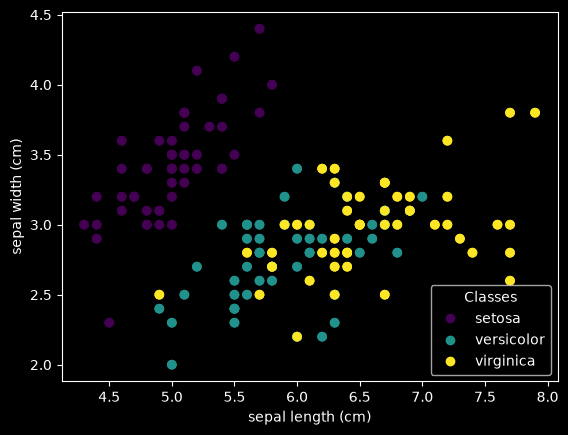

In [63]:
X, y = load_iris(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

_, ax = plt.subplots()
scatter = ax.scatter(X[:, 0], X[:, 1], c=y)
ax.set(xlabel=iris.feature_names[0], ylabel=iris.feature_names[1])
_ = ax.legend(
    scatter.legend_elements()[0], iris.target_names, loc="lower right", title="Classes"
)

scatter = ax.scatter(X[:, 0], X[:, 1], c=y)

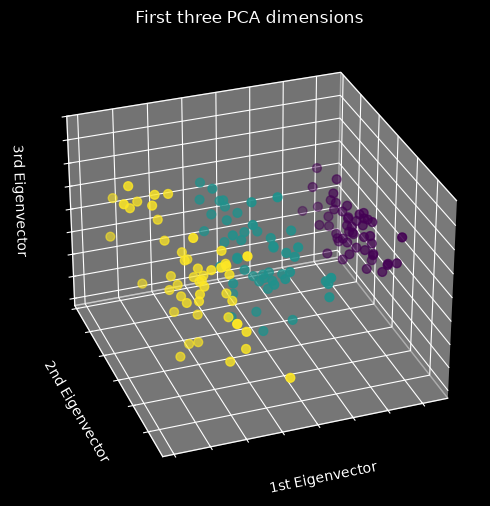

In [64]:
# From Scikit Learn website on the dataset
# unused but required import for doing 3d projections with matplotlib < 3.2
from sklearn.decomposition import PCA

fig = plt.figure(1, figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d", elev=-150, azim=110)

X_reduced = PCA(n_components=3).fit_transform(X)
ax.scatter(
    X_reduced[:, 0],
    X_reduced[:, 1],
    X_reduced[:, 2],
    c=y,
    s=40,
)

ax.set_title("First three PCA dimensions")
ax.set_xlabel("1st Eigenvector")
ax.xaxis.set_ticklabels([])
ax.set_ylabel("2nd Eigenvector")
ax.yaxis.set_ticklabels([])
ax.set_zlabel("3rd Eigenvector")
ax.zaxis.set_ticklabels([])

plt.show()

In [65]:
X

array([[5.1, 3.5, 1.4, 0.2],
       [4.9, 3. , 1.4, 0.2],
       [4.7, 3.2, 1.3, 0.2],
       [4.6, 3.1, 1.5, 0.2],
       [5. , 3.6, 1.4, 0.2],
       [5.4, 3.9, 1.7, 0.4],
       [4.6, 3.4, 1.4, 0.3],
       [5. , 3.4, 1.5, 0.2],
       [4.4, 2.9, 1.4, 0.2],
       [4.9, 3.1, 1.5, 0.1],
       [5.4, 3.7, 1.5, 0.2],
       [4.8, 3.4, 1.6, 0.2],
       [4.8, 3. , 1.4, 0.1],
       [4.3, 3. , 1.1, 0.1],
       [5.8, 4. , 1.2, 0.2],
       [5.7, 4.4, 1.5, 0.4],
       [5.4, 3.9, 1.3, 0.4],
       [5.1, 3.5, 1.4, 0.3],
       [5.7, 3.8, 1.7, 0.3],
       [5.1, 3.8, 1.5, 0.3],
       [5.4, 3.4, 1.7, 0.2],
       [5.1, 3.7, 1.5, 0.4],
       [4.6, 3.6, 1. , 0.2],
       [5.1, 3.3, 1.7, 0.5],
       [4.8, 3.4, 1.9, 0.2],
       [5. , 3. , 1.6, 0.2],
       [5. , 3.4, 1.6, 0.4],
       [5.2, 3.5, 1.5, 0.2],
       [5.2, 3.4, 1.4, 0.2],
       [4.7, 3.2, 1.6, 0.2],
       [4.8, 3.1, 1.6, 0.2],
       [5.4, 3.4, 1.5, 0.4],
       [5.2, 4.1, 1.5, 0.1],
       [5.5, 4.2, 1.4, 0.2],
       [4.9, 3

In [66]:
# standardize with the training set's statistics only
mean, std = X_train.mean(axis=0), X_train.std(axis=0)
X_train = (X_train - mean) / std
X_test = (X_test - mean) / std

## Generelle Überlegungen
- Die Iris Daten haben wie oben gesehen, vier Features, dementsprechend ist der Inputlayer vier Neuronen gross.
- Der Hidden Layer kann theoretisch beliebig gross sein, wir können 8 Neuronen mit einer Aktivierungsfunktion, z.B. Sigmoid oder Tanh nehmen
- Ich interpretiere die Aufgabe als Klassifikator-Aufgabe, somit ist der Output 3 Neuronen gross. Wir könnten z.B. softmax verwenden, sodass wir schlussendlich
- eine Wahrscheinlichkeit pro Klasse haben.

### Notation
Der Einfachheit halber führe ich kurz die Notation, die ich verwenden werde ein:
- $X$: Input
- $y$: Output
- $n$: Anzahl Zeilen im Input
- $W_n$: Gewicht $n$
- $h$: Anzahl der Neuronen im Hidden Layer
- $b$: Bias. Jedes Neuron hat einen Bias, welcher trainierbar ist.
- $A$: Aktivierungsfunktion
- $L$: Loss-Funktion
- $dW_n$: Ableitung von $W_n$, definiert als $dW_n = \frac{\partial L}{\partial W_n}$
- $\sigma'$: Ableitung der Aktivierungsfunktion, definiert als $\sigma'(Z_1) = \frac{\partial A_1}{\partial Z_1}$

### Mathematische Überlegungen
Ein Neuron berechnet eine gewichtete Summe seiner Inputs plus einen Bias:
$$
z = w_1 \cdot x_1 + w_2 \cdot x_2 + \dots + w_n \cdot x_n + b
$$

Die Matrix $Z = XW_1 + b_1$ nutzt Numpy's Fähigkeit des Broadcastings aus und fügt denselben Bias jeder Zeile hinzu. Darum hat jeder Bias die Form von $(1, n)$ bzw. $(n, h)$.

## Umsetzung
- Die Samples werden als Zeilen beibehalten. Somit ist $X = (n, 4)$.
-

Die Gewichte sind $W_1: (4, h)$, $b_1: (1, h)$, $W_2: (h, 3)$, $b_2: (1, 3)$

### Forward Pass (Predict)
$$
Z_1 = XW_1 + b_1, \quad A_1 = \sigma(Z_1)
$$
$$
Z_2 = A_1 \cdot W_2 + b_2
$$
$$\hat{Y} = softmax(Z_2)$$


### Backward Pass (Fit)
Für `fit` können wir einen cross-entropy Loss nehmen, wobei wir die y Werte via one-hot-encoding der Dimension $(n, 3)$ darstellen können.
Dann nehmen wir den Gradienten step für jeden Parameter, z.B. `W1 -= lr * dW1`.
`fit()` ist ein Loop über alle Epochen.

Mathematisch sieht das etwa wie folgt aus:
$$dZ_2 = \frac{\hat{Y} - Y}{n}$$
$$dW2 = A^{T}_1 \cdot dZ_2$$
$$b_2 = \sum_{rows} dZ_2$$
$$dZ_1 = (dZ_2 \cdot W^{T}_2) \odot \sigma' (Z_1), \quad \sigma'(z) = \sigma(z)(1- \sigma(z))$$
$$dW1_1 = X^T dZ, \quad db_1 = \sum_{rows} dZ_1$$

Der Loss ist definiert als
$$ L = -\frac{1}{n}\sum\sum Y \log(\hat{Y})$$

In [111]:
# --- Hidden-layer activations and their derivatives ---

def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -500, 500)))

def sigmoid_derivative(z):
    s = sigmoid(z)
    return s * (1 - s)


def tanh(z):
    return np.tanh(z)

def tanh_derivative(z):
    return 1 - np.tanh(z) ** 2


def relu(z):
    return np.maximum(0, z)

def relu_derivative(z):
    return (z > 0).astype(float)


# --- Output layer (fixed, not user-selectable) ---

def softmax(z):
    e = np.exp(z - z.max(axis=1, keepdims=True))  # subtract max for numerical stability
    return e / e.sum(axis=1, keepdims=True)


# --- Registry ---

class ActivationName(StrEnum):
    SIGMOID = "sigmoid"
    TANH = "tanh"
    RELU = "relu"


@dataclass(frozen=True)
class Activation:
    fn: Callable[[np.ndarray], np.ndarray]
    derivative: Callable[[np.ndarray], np.ndarray]


ACTIVATIONS: dict[ActivationName, Activation] = {
    ActivationName.SIGMOID: Activation(sigmoid, sigmoid_derivative),
    ActivationName.TANH: Activation(tanh, tanh_derivative),
    ActivationName.RELU: Activation(relu, relu_derivative),
}

class MyBaseNeuralNet:  # myNeuralNet -> MyNeuralNet; ruff complains and insert Base
    def __init__(self, n_input: int, n_hidden: int, n_output: int, lr: float =0.1, seed: int=42, activation_function: ActivationName | str = ActivationName.SIGMOID):
        self.a_function = activation_function
        rng = np.random.default_rng(seed)
        self.W1 = rng.normal(0, 0.5, (n_input, n_hidden))
        self.b1 = np.zeros((1, n_hidden))
        self.W2 = rng.normal(0, 0.5, (n_hidden, n_output))
        self.b2 = np.zeros((1, n_output))
        self.lr = lr
        self.activation_function = ACTIVATIONS[activation_function]
        self.losses: list[float] = []

    def _forward(self, X: np.ndarray) -> np.ndarray:
        self.Z1 = X @ self.W1 + self.b1
        self.A1 = self.activation_function.fn(self.Z1)
        self.Z2 = self.A1 @ self.W2 + self.b2
        return softmax(self.Z2)

    def _return_proba(self, X: np.ndarray) -> np.ndarray:
        return self._forward(X)

    def _update(self, value, dValue):
        return value - self.lr * dValue

    def fit(self, X: np.ndarray, y: np.ndarray, epochs: int = 1000):
        n = X.shape[0]
        Y = np.eye(self.W2.shape[1])[y]  # one-hot encoding: class 2 --> [0, 0, 1]
        for epoch in range(1, epochs + 1, 1):
            Y_hat = self._forward(X)

            # 1. compute dZ2, dW2, db2
            dZ2 = (Y_hat - Y) / n
            dW2 = np.dot(self.A1.T, dZ2)
            db2 = np.sum(dZ2, axis=0)

            # 2. compute dZ1 using self.activation.derivative(self.Z1), then dW1 and db1
            dZ1 = (dZ2 @ self.W2.T) * self.activation_function.derivative(self.Z1)
            dW1 = np.dot(X.T, dZ1)
            db1 = np.sum(dZ1, axis=0)


            # 3. update: self.W1 -= self.lr * dW1, and so on for all four parameters
            self.W1 = self._update(self.W1, dW1)
            self.b1 = self._update(self.b1, db1)
            self.W2 = self._update(self.W2, dW2)
            self.b2 = self._update(self.b2, db2)

            # 4. Log the loss every 100th iteration for sanity checking
            loss = -np.mean(np.sum(Y * np.log(Y_hat + 1e-12), axis=1))
            self.losses.append(loss)
            if epoch % 100 == 0:

                print(f"Epoch {epoch}: loss = {loss:.4f}")
        return self

    def predict(self, X: np.ndarray) -> np.ndarray:
        return self._forward(X).argmax(axis=1)

    def plot_loss(self):
        plt.plot(self.losses)

        plt.xlabel("Epoch")
        plt.ylabel("Cross-entropy loss")
        plt.title(f"Training Loss for NN with activation function {self.a_function}")
        plt.show()


Neural Net with activation function: tanh
Epoch 100: loss = 0.2922
Epoch 200: loss = 0.1749
Epoch 300: loss = 0.1161
Epoch 400: loss = 0.0897
Epoch 500: loss = 0.0759
Epoch 600: loss = 0.0676
Epoch 700: loss = 0.0620
Epoch 800: loss = 0.0581
Epoch 900: loss = 0.0551
Epoch 1000: loss = 0.0528
Test accuracy: 96.67%


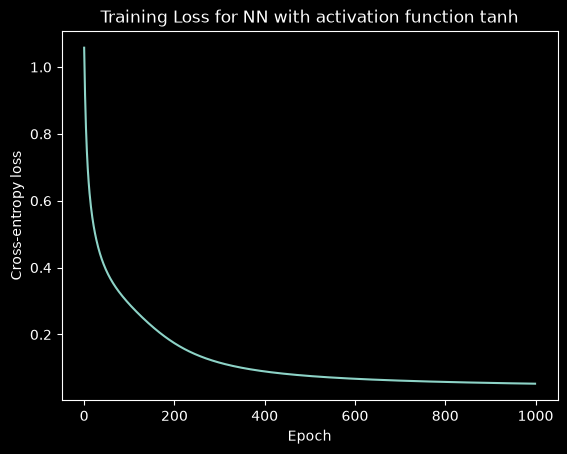

In [112]:
activation_fn = ActivationName.TANH
print(f"Neural Net with activation function: {activation_fn}")
nn = MyBaseNeuralNet(4, 8, 3, activation_function=activation_fn)
nn.fit(X_train, y_train, epochs=1000)

accuracy = (nn.predict(X_test) == y_test).mean()
print(f"Test accuracy: {accuracy:.2%}")
nn.plot_loss()

Neural Net with activation function: sigmoid
Epoch 100: loss = 0.5585
Epoch 200: loss = 0.4163
Epoch 300: loss = 0.3485
Epoch 400: loss = 0.3034
Epoch 500: loss = 0.2674
Epoch 600: loss = 0.2360
Epoch 700: loss = 0.2079
Epoch 800: loss = 0.1835
Epoch 900: loss = 0.1631
Epoch 1000: loss = 0.1464
Test accuracy: 96.67%


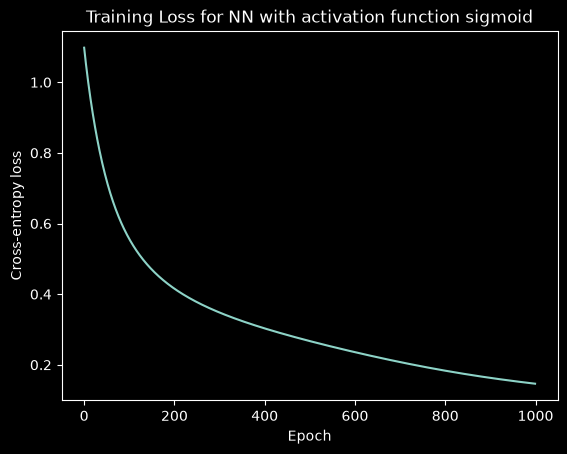

In [113]:
activation_fn = ActivationName.SIGMOID
print(f"Neural Net with activation function: {activation_fn}")
nn = MyBaseNeuralNet(4, 8, 3, activation_function=activation_fn)
nn.fit(X_train, y_train, epochs=1000)

accuracy = (nn.predict(X_test) == y_test).mean()
print(f"Test accuracy: {accuracy:.2%}")
nn.plot_loss()

Neural Net with activation function: relu
Epoch 100: loss = 0.2810
Epoch 200: loss = 0.1701
Epoch 300: loss = 0.1148
Epoch 400: loss = 0.0875
Epoch 500: loss = 0.0726
Epoch 600: loss = 0.0639
Epoch 700: loss = 0.0582
Epoch 800: loss = 0.0543
Epoch 900: loss = 0.0514
Epoch 1000: loss = 0.0491
Test accuracy: 96.67%


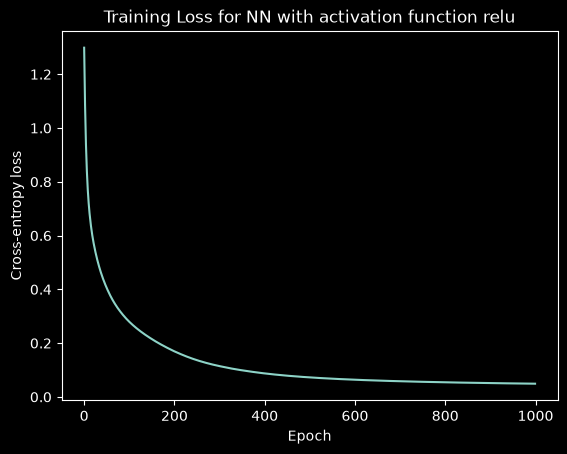

In [114]:
activation_fn = ActivationName.RELU
print(f"Neural Net with activation function: {activation_fn}")
nn = MyBaseNeuralNet(4, 8, 3, activation_function=activation_fn)
nn.fit(X_train, y_train, epochs=1000)

accuracy = (nn.predict(X_test) == y_test).mean()
print(f"Test accuracy: {accuracy:.2%}")
nn.plot_loss()

Neural Net with activation function: relu
Epoch 100: loss = 0.2249
Epoch 200: loss = 0.1265
Epoch 300: loss = 0.0886
Epoch 400: loss = 0.0715
Epoch 500: loss = 0.0621
Epoch 600: loss = 0.0561
Epoch 700: loss = 0.0520
Epoch 800: loss = 0.0488
Epoch 900: loss = 0.0463
Epoch 1000: loss = 0.0444
Test accuracy: 96.67%


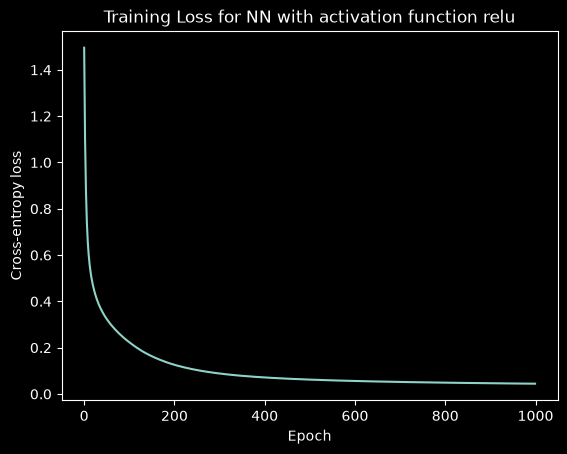

In [116]:
activation_fn = ActivationName.RELU
print(f"Neural Net with activation function: {activation_fn}")
nn = MyBaseNeuralNet(4, 16, 3, activation_function=activation_fn)
nn.fit(X_train, y_train, epochs=1000)

accuracy = (nn.predict(X_test) == y_test).mean()
print(f"Test accuracy: {accuracy:.2%}")
nn.plot_loss()

Epoch 100: loss = 0.5585
Epoch 200: loss = 0.4163
Epoch 300: loss = 0.3485
Epoch 400: loss = 0.3034
Epoch 500: loss = 0.2674
Epoch 600: loss = 0.2360
Epoch 700: loss = 0.2079
Epoch 800: loss = 0.1835
Epoch 900: loss = 0.1631
Epoch 1000: loss = 0.1464
Epoch 100: loss = 0.4419
Epoch 200: loss = 0.3249
Epoch 300: loss = 0.2649
Epoch 400: loss = 0.2234
Epoch 500: loss = 0.1918
Epoch 600: loss = 0.1672
Epoch 700: loss = 0.1477
Epoch 800: loss = 0.1324
Epoch 900: loss = 0.1203
Epoch 1000: loss = 0.1105
Epoch 100: loss = 0.3505
Epoch 200: loss = 0.2681
Epoch 300: loss = 0.2196
Epoch 400: loss = 0.1855
Epoch 500: loss = 0.1604
Epoch 600: loss = 0.1415
Epoch 700: loss = 0.1271
Epoch 800: loss = 0.1159
Epoch 900: loss = 0.1070
Epoch 1000: loss = 0.0998
Epoch 100: loss = 0.2613
Epoch 200: loss = 0.1874
Epoch 300: loss = 0.1492
Epoch 400: loss = 0.1263
Epoch 500: loss = 0.1112
Epoch 600: loss = 0.1005
Epoch 700: loss = 0.0927
Epoch 800: loss = 0.0866
Epoch 900: loss = 0.0818
Epoch 1000: loss = 0.0

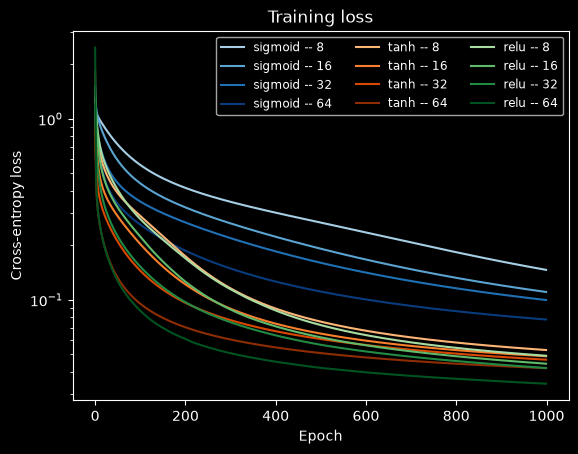

In [118]:
cmaps = {
    ActivationName.SIGMOID: plt.cm.Blues,
    ActivationName.TANH: plt.cm.Oranges,
    ActivationName.RELU: plt.cm.Greens,
}
sizes = [8, 16, 32, 64]
shades = np.linspace(0.35, 0.95, len(sizes))  # light for small, dark for large

for activation_fn in ActivationName:
    for hidden_layer_size, shade in zip(sizes, shades):
        nn = MyBaseNeuralNet(4, hidden_layer_size, 3, activation_function=activation_fn).fit(
            X_train, y_train, epochs=1000
        )
        plt.plot(nn.losses, color=cmaps[activation_fn](shade),
                 label=f"{activation_fn} -- {hidden_layer_size}")

plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.title("Training loss")
plt.yscale("log")
plt.legend(ncol=3, fontsize="small")
plt.show()


__Aufgabe 3__

- Installiere/Importiere TensorFlow 2 (fällt weg mit Colab - check welche TF-Version!)
- Erstelle ein Neuronales Netz mit einem Hidden Layer mit Keras.

In [122]:
import keras
from keras import layers, Sequential


class MyKerasNeuralNet:
    def __init__(self, n_input: int, n_hidden: int, n_output: int, lr: float = 0.001, seed: int = 42,
                 activation_function: ActivationName | str = ActivationName.SIGMOID):
        keras.utils.set_random_seed(seed)
        self.losses = []
        self.model = Sequential([
            keras.Input(shape=(n_input,)),
            layers.Dense(n_hidden, activation=str(ActivationName(activation_function))),
            layers.Dense(n_output, activation="softmax"),
        ])
        self.model.compile(
            optimizer=keras.optimizers.Adam(learning_rate=lr),
            loss="sparse_categorical_crossentropy",
            metrics=["accuracy"],
        )

    def fit(self, X: np.ndarray, y: np.ndarray, epochs: int = 1000):
        history = self.model.fit(X, y, epochs=epochs, batch_size=len(X), verbose=0)
        self.losses = history.history["loss"]
        return self

    def predict(self, X: np.ndarray) -> np.ndarray:
        return self.model.predict(X, verbose=0).argmax(axis=1)

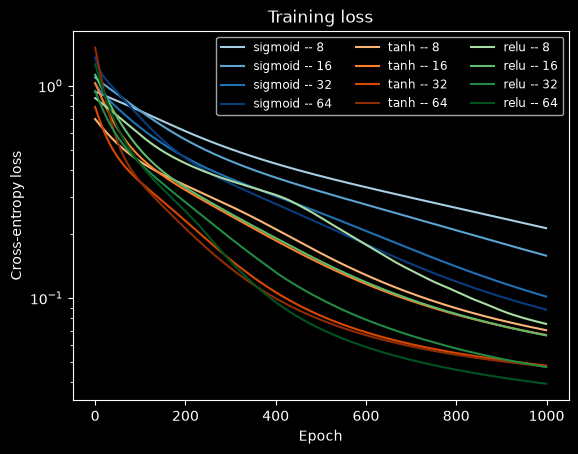

In [123]:
cmaps = {
    ActivationName.SIGMOID: plt.cm.Blues,
    ActivationName.TANH: plt.cm.Oranges,
    ActivationName.RELU: plt.cm.Greens,
}
sizes = [8, 16, 32, 64]
shades = np.linspace(0.35, 0.95, len(sizes))  # light for small, dark for large

for activation_fn in ActivationName:
    for hidden_layer_size, shade in zip(sizes, shades):
        nn = MyKerasNeuralNet(4, hidden_layer_size, 3, activation_function=activation_fn).fit(
            X_train, y_train, epochs=1000
        )
        plt.plot(nn.losses, color=cmaps[activation_fn](shade),
                 label=f"{activation_fn} -- {hidden_layer_size}")

plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.title("Training loss")
plt.yscale("log")
plt.legend(ncol=3, fontsize="small")
plt.show()

__Aufgabe 4__


- Installiere/Importiere pytorch (geht natürlich auch auf colab)
- Erstelle ein einfaches Neuronales Netz mit einem Hidden Layer mit pytorch.

In [127]:
import torch
from torch import nn

TORCH_ACTIVATIONS: dict[ActivationName, type[nn.Module]] = {
    ActivationName.SIGMOID: nn.Sigmoid,
    ActivationName.TANH: nn.Tanh,
    ActivationName.RELU: nn.ReLU,
}


class MyPytorchNeuralNet:
    def __init__(self, n_input: int, n_hidden: int, n_output: int, lr: float = 0.1, seed: int = 42,
                 activation_function: ActivationName | str = ActivationName.SIGMOID):
        torch.manual_seed(seed)
        self.losses = []
        self.model = nn.Sequential(
            nn.Linear(n_input, n_hidden),                                  # W1, b1
            TORCH_ACTIVATIONS[ActivationName(activation_function)](),     # hidden activation
            nn.Linear(n_hidden, n_output),                                 # W2, b2 (no softmax!)
        )
        self.loss_fn = nn.CrossEntropyLoss()
        self.optimizer = torch.optim.SGD(self.model.parameters(), lr=lr)

    def fit(self, X: np.ndarray, y: np.ndarray, epochs: int = 1000):
        X_t = torch.tensor(X, dtype=torch.float32)
        y_t = torch.tensor(y, dtype=torch.long)
        self.model.train()
        for _ in range(epochs):
            self.optimizer.zero_grad()           # reset gradients from the previous epoch
            logits = self.model(X_t)             # forward pass
            loss = self.loss_fn(logits, y_t)
            loss.backward()                      # backward pass: computes all dW, db
            self.optimizer.step()                # update: W -= lr * dW
            self.losses.append(loss.item())
        return self

    def predict(self, X: np.ndarray) -> np.ndarray:
        self.model.eval()
        with torch.no_grad():
            logits = self.model(torch.tensor(X, dtype=torch.float32))
        return logits.argmax(dim=1).numpy()

In [ ]:
sizes = [8, 16, 32, 64]
shades = np.linspace(0.35, 0.95, len(sizes))  # light for small, dark for large

for activation_fn in ActivationName:
    for hidden_layer_size, shade in zip(sizes, shades):
        nn = MyPytorchNeuralNet(4, hidden_layer_size, 3, activation_function=activation_fn).fit(
            X_train, y_train, epochs=1000
        )
        plt.plot(nn.losses, color=cmaps[activation_fn](shade),
                 label=f"{activation_fn} -- {hidden_layer_size}")


plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.title("Training loss")
plt.yscale("log")
plt.legend(ncol=3, fontsize="small")
plt.show()

__Aufgabe 5__ (optional)
- Versuche die Klasse so umzuformulieren, dass sie als SciKit-Klassifizierer verwendet werden kann. [Beschreibung](http://danielhnyk.cz/creating-your-own-estimator-scikit-learn/)


In [ ]:
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.utils.validation import check_array, check_is_fitted, check_X_y


class MyNeuralNet(ClassifierMixin, BaseEstimator):
    def __init__(self, n_hidden: int = 8,
                 activation_function: ActivationName | str = ActivationName.SIGMOID,
                 lr: float = 0.1, epochs: int = 1000, seed: int = 42):
        self.n_hidden = n_hidden
        self.activation_function = activation_function
        self.lr = lr
        self.epochs = epochs
        self.seed = seed

    def _forward(self, X):
        Z1 = X @ self.W1_ + self.b1_
        A1 = self.activation_.fn(Z1)
        Z2 = A1 @ self.W2_ + self.b2_
        return Z1, A1, softmax(Z2)

    def fit(self, X, y):
        X, y = check_X_y(X, y)
        self.classes_, y_idx = np.unique(y, return_inverse=True)  # labels -> 0..k-1
        self.n_features_in_ = X.shape[1]
        self.activation_ = ACTIVATIONS[ActivationName(self.activation_function)]

        n, n_input = X.shape
        n_output = len(self.classes_)
        rng = np.random.default_rng(self.seed)
        self.W1_ = rng.normal(0, 0.5, (n_input, self.n_hidden))
        self.b1_ = np.zeros((1, self.n_hidden))
        self.W2_ = rng.normal(0, 0.5, (self.n_hidden, n_output))
        self.b2_ = np.zeros((1, n_output))

        Y = np.eye(n_output)[y_idx]
        self.losses_ = []
        for _ in range(self.epochs):
            Z1, A1, Y_hat = self._forward(X)
            self.losses_.append(-np.mean(np.sum(Y * np.log(Y_hat + 1e-12), axis=1)))

            dZ2 = (Y_hat - Y) / n
            dW2 = A1.T @ dZ2
            db2 = dZ2.sum(axis=0, keepdims=True)
            dZ1 = (dZ2 @ self.W2_.T) * self.activation_.derivative(Z1)
            dW1 = X.T @ dZ1
            db1 = dZ1.sum(axis=0, keepdims=True)

            self.W1_ -= self.lr * dW1
            self.b1_ -= self.lr * db1
            self.W2_ -= self.lr * dW2
            self.b2_ -= self.lr * db2
        return self

    def predict_proba(self, X):
        check_is_fitted(self)
        X = check_array(X)
        if X.shape[1] != self.n_features_in_:
            raise ValueError(f"Expected {self.n_features_in_} features, got {X.shape[1]}")
        return self._forward(X)[2]

    def predict(self, X):
        return self.classes_[self.predict_proba(X).argmax(axis=1)]

In [ ]:
from sklearn.datasets import load_iris
from sklearn.model_selection import GridSearchCV, cross_val_score, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

X, y = load_iris(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

pipe = make_pipeline(StandardScaler(), MyNeuralNet(n_hidden=16, activation_function="tanh"))

# cross-validation
scores = cross_val_score(pipe, X_train, y_train, cv=5)
print(f"CV accuracy: {scores.mean():.2%} ± {scores.std():.2%}")

# hyperparameter search: replaces your manual double loop
grid = GridSearchCV(
    pipe,
    param_grid={
        "myneuralnet__n_hidden": [8, 16, 32, 64],
        "myneuralnet__activation_function": list(ActivationName),
    },
    cv=5,
)
grid.fit(X_train, y_train)
print("Best params:", grid.best_params_)
print(f"Test accuracy: {grid.score(X_test, y_test):.2%}")